In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [1]:
!pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.8 MB/s  0:00:11


In [3]:
df=pd.read_csv('healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


| Column                | المعنى                                                                                                      | مثال                                        |
| --------------------- | ----------------------------------------------------------------------------------------------------------- | ------------------------------------------- |
| **id**                | رقم تعريفي مميز لكل شخص، يستخدم للتعرف على الشخص وليس للتنبؤ بالسكتة غالبًا.                                | `9046`                                      |
| **gender**            | جنس الشخص.                                                                                                  | `Male` / `Female`                           |
| **age**               | عمر الشخص بالسنوات.                                                                                         | `67.0` = عمره 67 سنة                        |
| **hypertension**      | هل الشخص لديه **ضغط دم مرتفع**؟ `1` = نعم، `0` = لا.                                                        | `0`                                         |
| **heart_disease**     | هل الشخص لديه **مرض في القلب**؟ `1` = نعم، `0` = لا.                                                        | `1`                                         |
| **ever_married**      | هل الشخص تزوج من قبل؟                                                                                       | `Yes` / `No`                                |
| **work_type**         | نوع العمل الذي يعمل به الشخص.                                                                               | `Private`, `Self-employed`                  |
| **Residence_type**    | نوع مكان الإقامة.                                                                                           | `Urban` = مدينة، `Rural` = ريف              |
| **avg_glucose_level** | متوسط مستوى **الجلوكوز/سكر الدم** في الدم، وعادة يقاس بـ mg/dL.                                             | `228.69`                                    |
| **bmi**               | **Body Mass Index** = مؤشر كتلة الجسم، ويعطي فكرة عن الوزن بالنسبة للطول.                                   | `36.6`                                      |
| **smoking_status**    | حالة التدخين.                                                                                               | `never smoked`, `formerly smoked`, `smokes` |
| **stroke**            | هل الشخص أصيب بسكتة دماغية؟ وهذا هو غالبًا **Target/Label** الذي نريد التنبؤ به. `1` = أصيب، `0` = لم يُصب. | `1`                                         |


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
df.shape

(5110, 12)

In [7]:
df.columns.tolist()

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

In [8]:
df.drop(columns=['id'], inplace=True)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


Text(0.5, 1.0, 'Distribution of BMI')

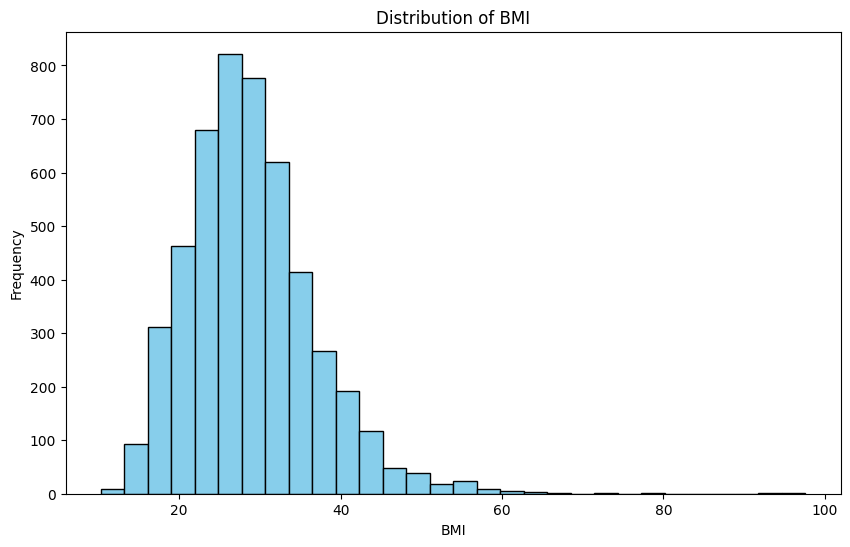

In [11]:
plt.figure(figsize=(10,6))
plt.hist(df['bmi'].dropna(), bins=30, color='skyblue', edgecolor='black')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.title('Distribution of BMI')

In [12]:
df['bmi'].skew()

np.float64(1.0553402052962912)

In [13]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df['bmi'] = imputer.fit_transform(df[['bmi']])


In [14]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


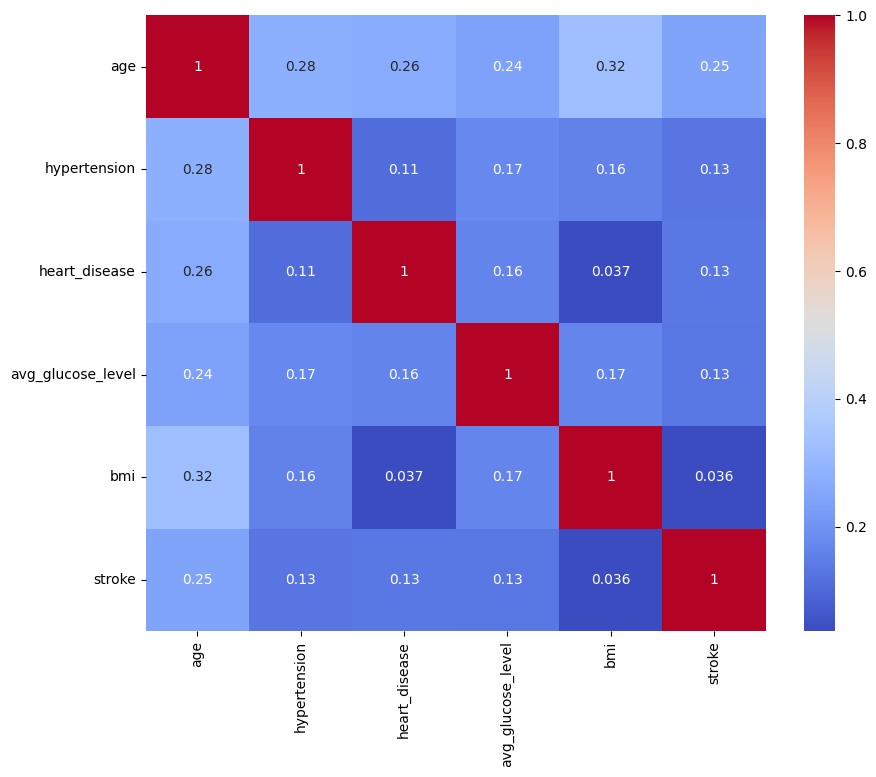

In [15]:
import seaborn as sns

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

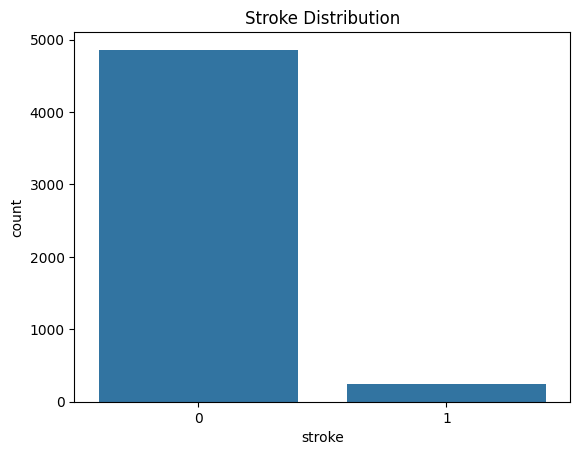

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='stroke')
plt.title('Stroke Distribution')
plt.show()

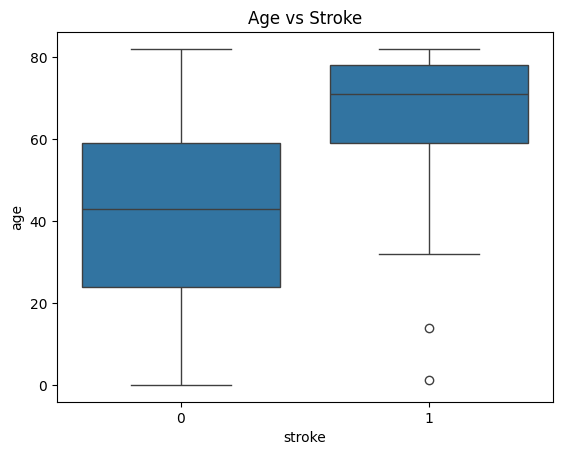

In [17]:
sns.boxplot(data=df, x='stroke', y='age')
plt.title('Age vs Stroke')
plt.show()

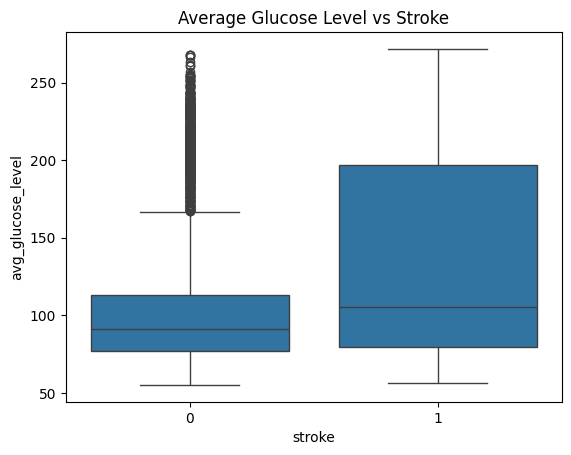

In [18]:
sns.boxplot(data=df, x='stroke', y='avg_glucose_level')
plt.title('Average Glucose Level vs Stroke')
plt.show()

In [19]:
df.select_dtypes(include=['object']).nunique()

,0
gender,3
ever_married,2
work_type,5
Residence_type,2
smoking_status,4


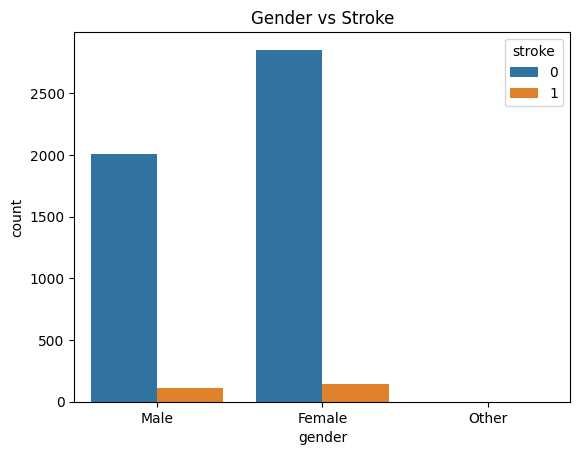

In [20]:
sns.countplot(data=df, x='gender', hue='stroke')
plt.title('Gender vs Stroke')
plt.show()

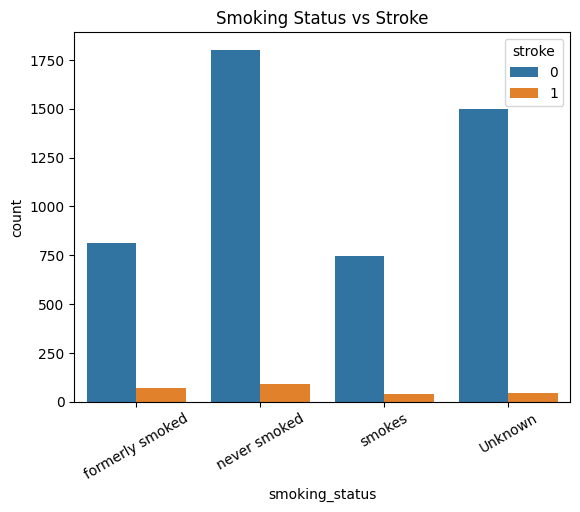

In [21]:
sns.countplot(data=df, x='smoking_status', hue='stroke')
plt.title('Smoking Status vs Stroke')
plt.xticks(rotation=30)
plt.show()

In [22]:
df.select_dtypes(include=['object']).nunique()

,0
gender,3
ever_married,2
work_type,5
Residence_type,2
smoking_status,4


In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['ever_married'] = le.fit_transform(df['ever_married'])
df['Residence_type'] = le.fit_transform(df['Residence_type'])



In [24]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    handle_unknown='ignore')
for col in ['gender', 'smoking_status', 'work_type']:

    ohe_encoded = ohe.fit_transform(df[[col]]).toarray()
    ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out([col]),
    index=df.index
    )
    df = pd.concat([df, ohe_df], axis=1)
    df.drop(col,axis =1 ,inplace =True)

In [25]:
X=df.drop('stroke', axis=1)
y=df['stroke']

In [26]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train = ",x_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",x_test.shape ," y_test  = ", y_test.shape)

X_train =  (4088, 19)  y_train =  (4088,)
X_test  =  (1022, 19)  y_test  =  (1022,)


In [27]:
x_train.isna().sum()

,0
age,0
hypertension,0
heart_disease,0
ever_married,0
Residence_type,0
avg_glucose_level,0
bmi,0
gender_Female,0
gender_Male,0
gender_Other,0


In [28]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred_lr = model_lr.predict(X_test_scaled)
y_proba_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

In [29]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_auc_score, average_precision_score,precision_score,recall_score,f1_score)

for name, y_pred, y_proba in [('Logistic Regression', y_pred_lr, y_proba_lr)]:

   print(f"===={name}====")
   print("Accuracy:", accuracy_score(y_test, y_pred))
   print(confusion_matrix(y_test, y_pred))
   print(classification_report(y_test, y_pred))
   print("ROC-AUC:", roc_auc_score(y_test, y_proba))
   print("PR-AUC:", average_precision_score(y_test, y_proba))
   print()

====Logistic Regression====
Accuracy: 0.952054794520548
[[972   0]
 [ 49   1]]
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

ROC-AUC: 0.8421399176954733
PR-AUC: 0.2703947245089946



In [30]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
results = []

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [31]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", max_depth=8, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric="logloss", scale_pos_weight=19, random_state=1),    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[723 249]
 [ 10  40]]


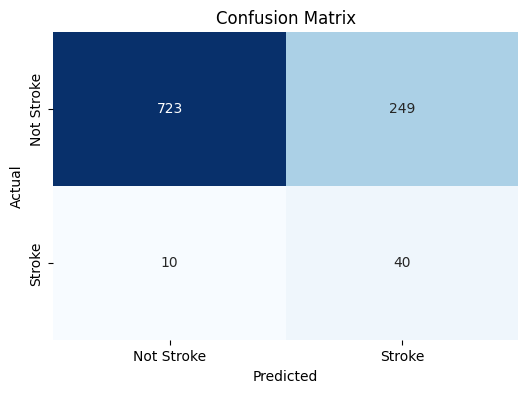


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

ROC-AUC: 0.84380658436214


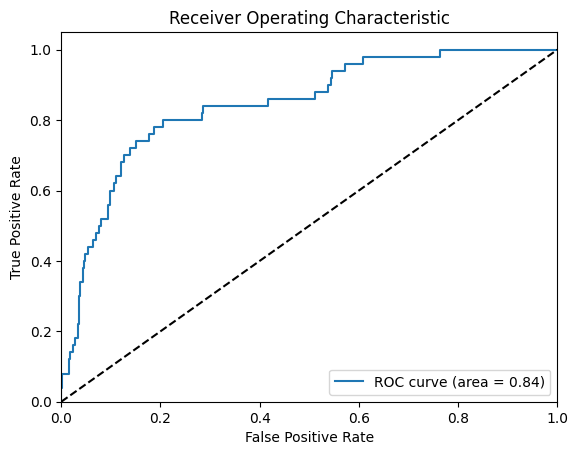

PR AUC: 0.2682015167509742


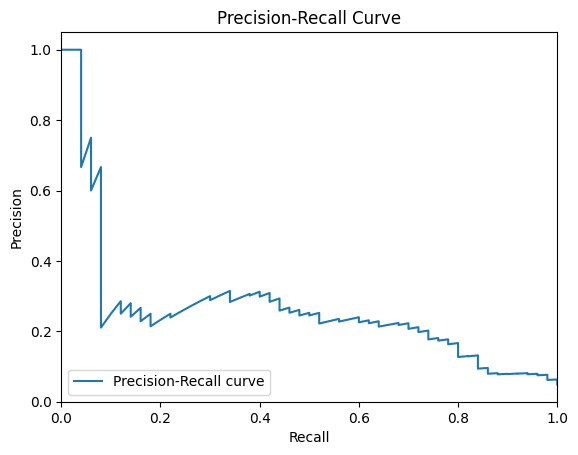

  8%|▊         | 1/13 [00:01<00:20,  1.70s/it]


Confusion Matrix:
 [[962  10]
 [ 50   0]]


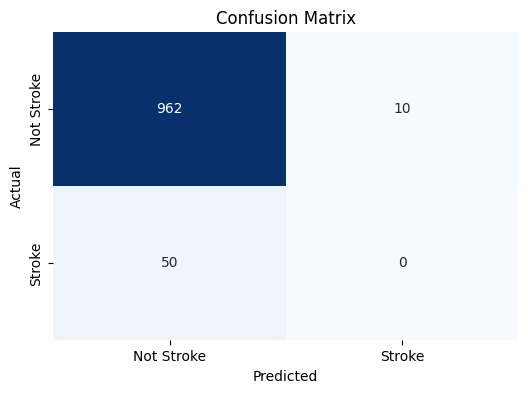


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.94      1022
   macro avg       0.48      0.49      0.48      1022
weighted avg       0.90      0.94      0.92      1022

ROC-AUC: 0.6666358024691358


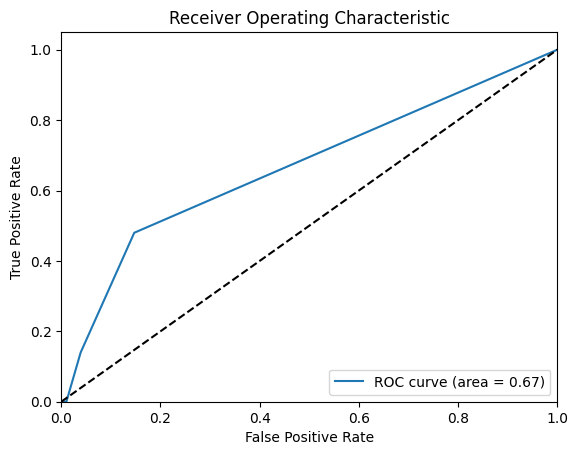

PR AUC: 0.09608036633842557


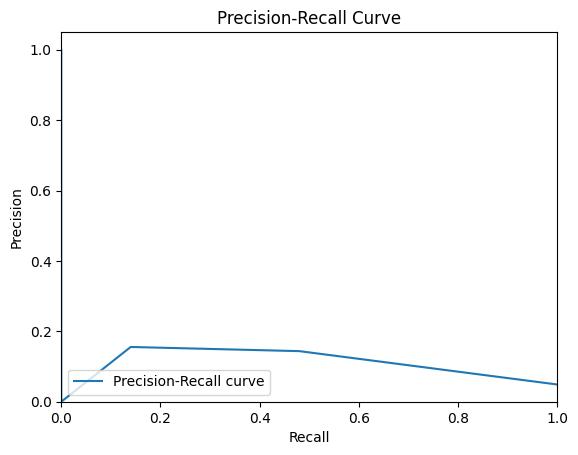

 15%|█▌        | 2/13 [00:02<00:14,  1.28s/it]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


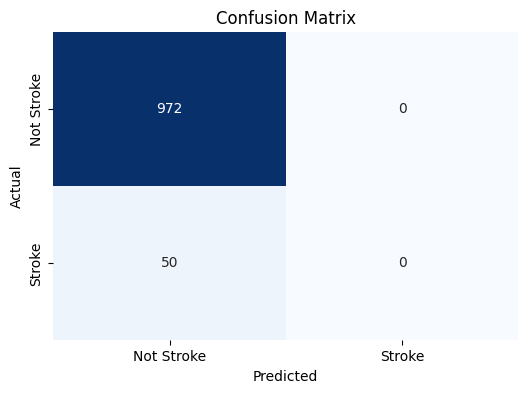


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.591275720164609


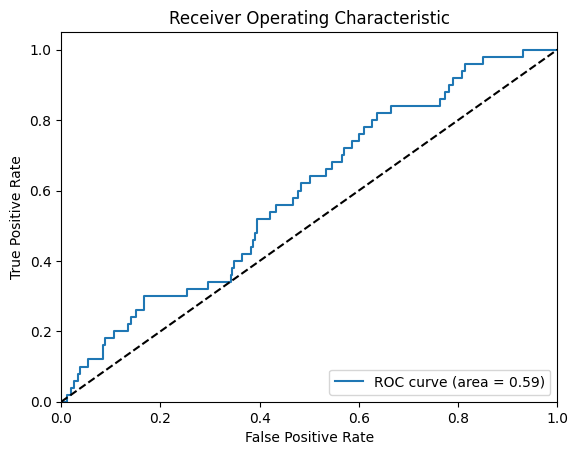

PR AUC: 0.06855818297516333


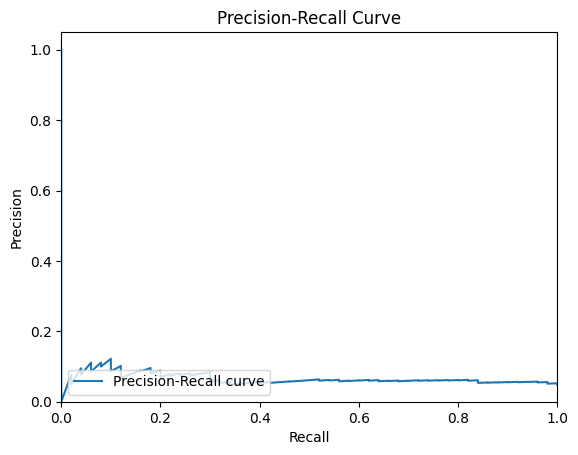

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:05<00:17,  1.75s/it]


Confusion Matrix:
 [[922  50]
 [ 40  10]]


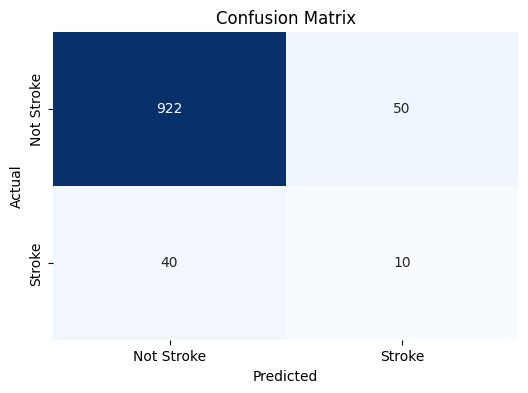


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.95      0.95       972
      Stroke       0.17      0.20      0.18        50

    accuracy                           0.91      1022
   macro avg       0.56      0.57      0.57      1022
weighted avg       0.92      0.91      0.92      1022

ROC-AUC: 0.5742798353909464


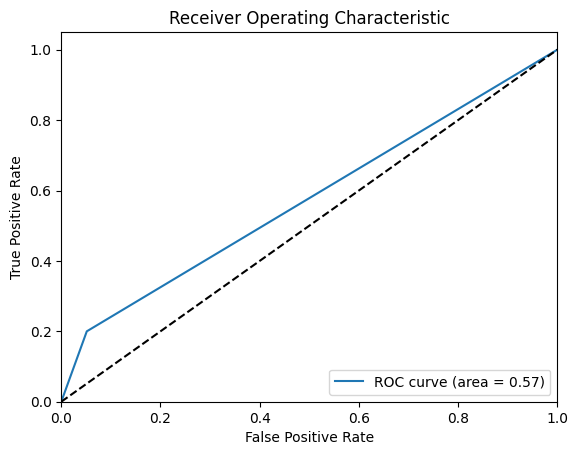

PR AUC: 0.07247227658186561


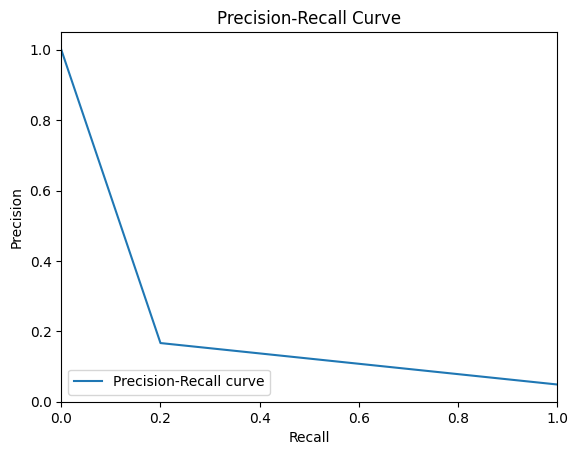

 31%|███       | 4/13 [00:05<00:11,  1.31s/it]


Confusion Matrix:
 [[395 577]
 [  3  47]]


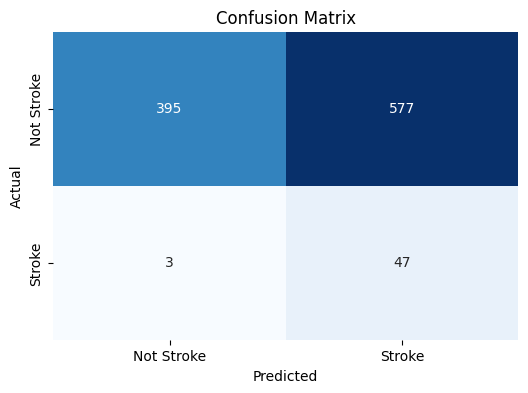


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.41      0.58       972
      Stroke       0.08      0.94      0.14        50

    accuracy                           0.43      1022
   macro avg       0.53      0.67      0.36      1022
weighted avg       0.95      0.43      0.56      1022

ROC-AUC: 0.7954526748971192


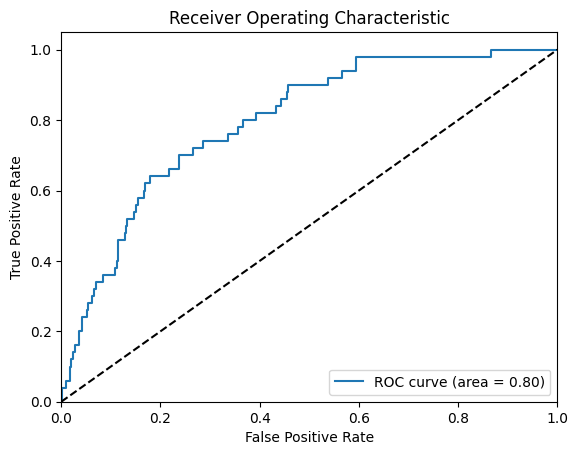

PR AUC: 0.17193910367498275


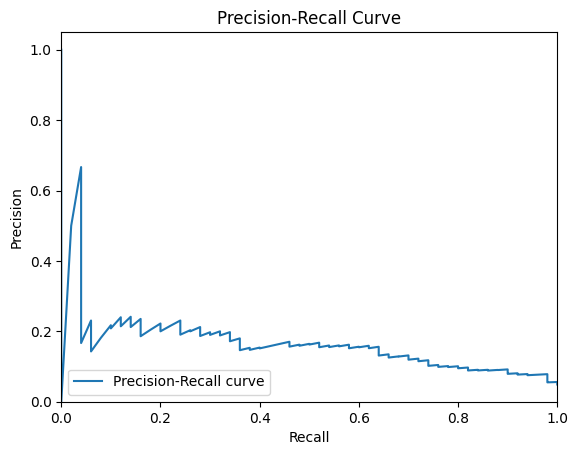

 38%|███▊      | 5/13 [00:06<00:09,  1.22s/it]


Confusion Matrix:
 [[864 108]
 [ 26  24]]


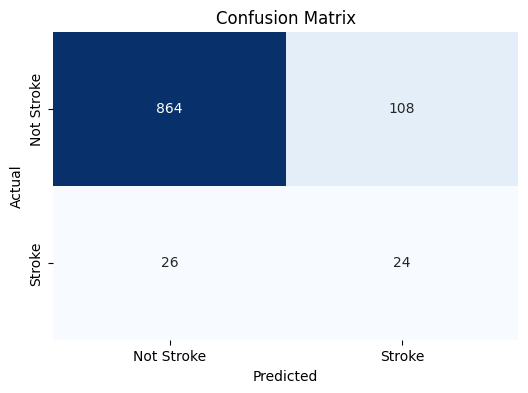


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.89      0.93       972
      Stroke       0.18      0.48      0.26        50

    accuracy                           0.87      1022
   macro avg       0.58      0.68      0.60      1022
weighted avg       0.93      0.87      0.90      1022

ROC-AUC: 0.8059670781893005


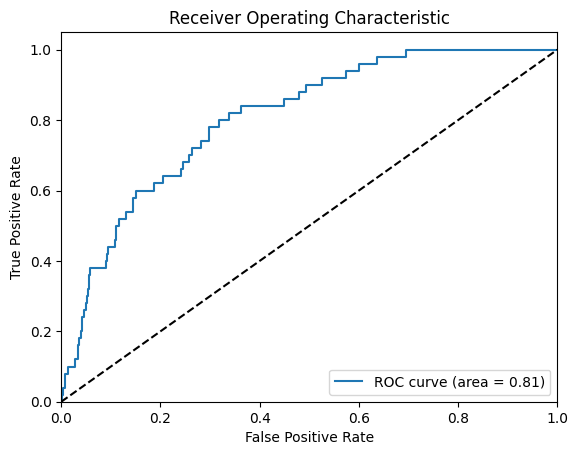

PR AUC: 0.17500291006854835


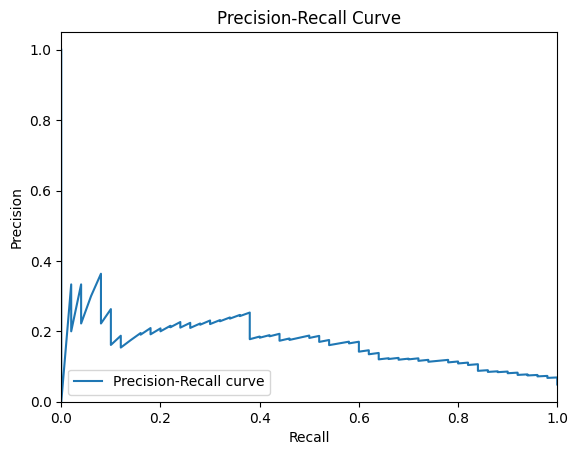

 46%|████▌     | 6/13 [00:08<00:10,  1.55s/it]


Confusion Matrix:
 [[962  10]
 [ 48   2]]


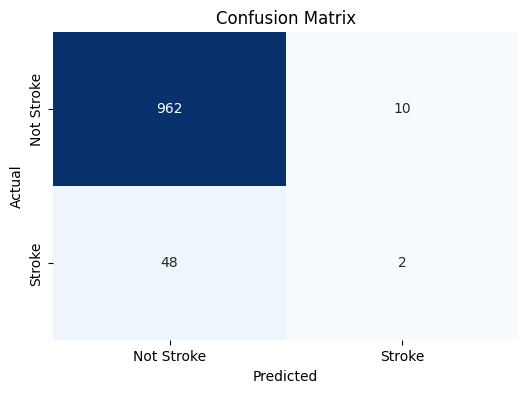


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.17      0.04      0.06        50

    accuracy                           0.94      1022
   macro avg       0.56      0.51      0.52      1022
weighted avg       0.91      0.94      0.93      1022

ROC-AUC: 0.7090843621399177


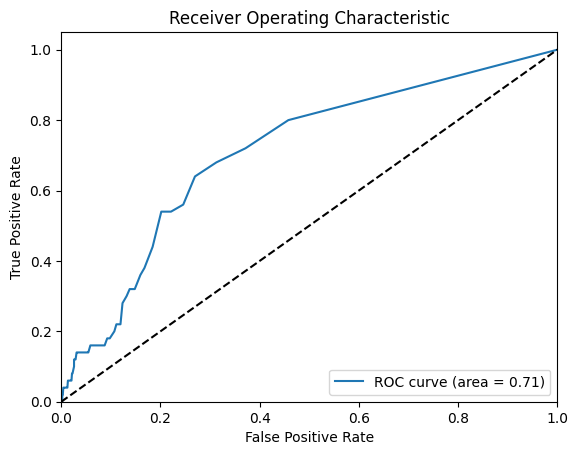

PR AUC: 0.10941711327294878


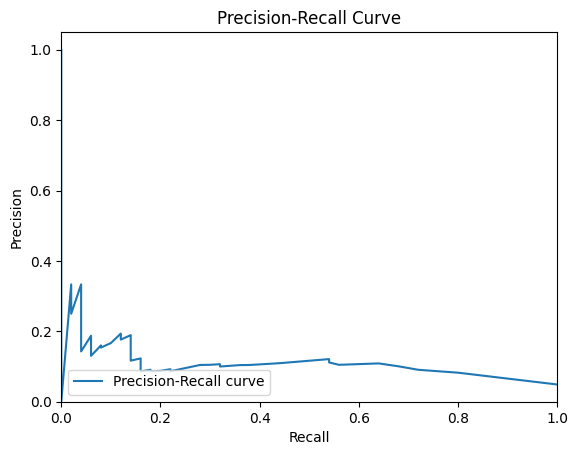

 54%|█████▍    | 7/13 [00:10<00:10,  1.72s/it]


Confusion Matrix:
 [[972   0]
 [ 50   0]]


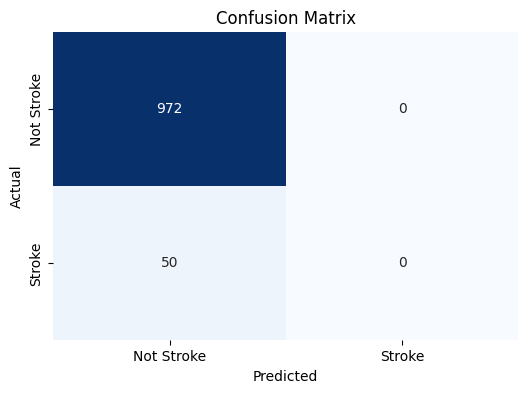


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

ROC-AUC: 0.8287448559670783


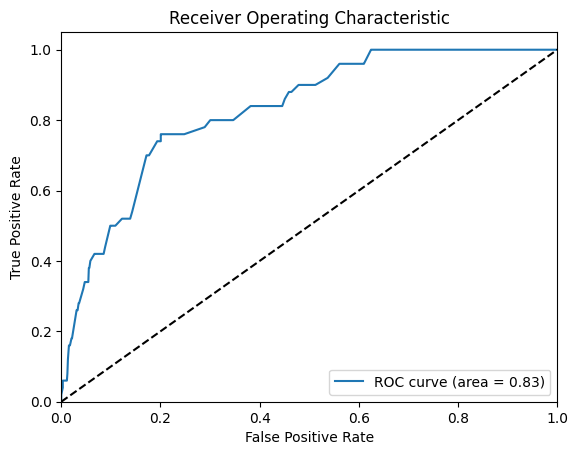

PR AUC: 0.22525228523943236


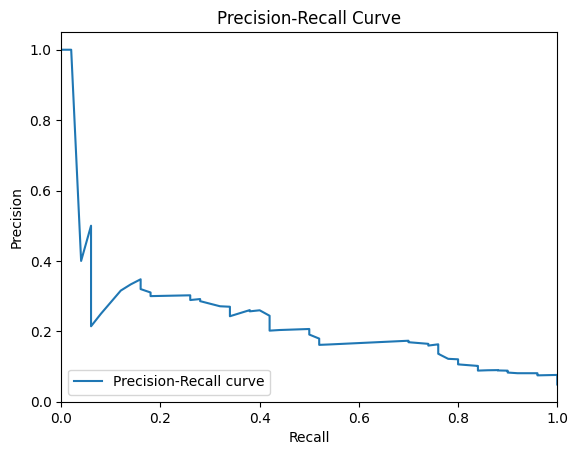

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:12<00:07,  1.58s/it]


Confusion Matrix:
 [[969   3]
 [ 49   1]]


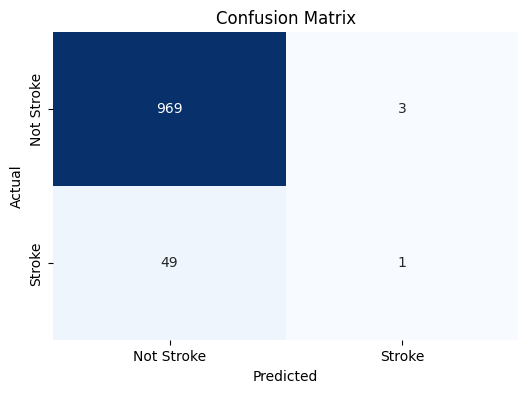


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      1.00      0.97       972
      Stroke       0.25      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.60      0.51      0.51      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8355761316872428


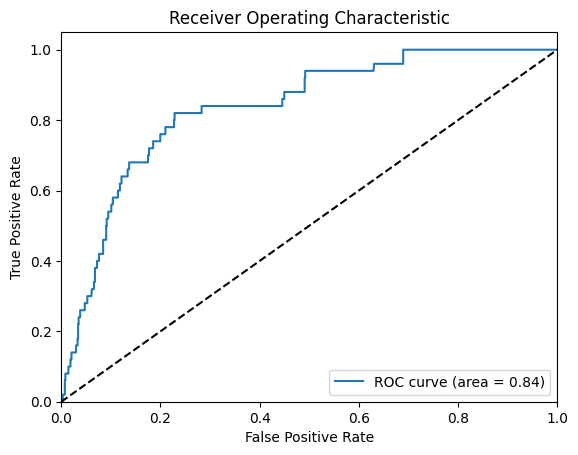

PR AUC: 0.19650676365307032


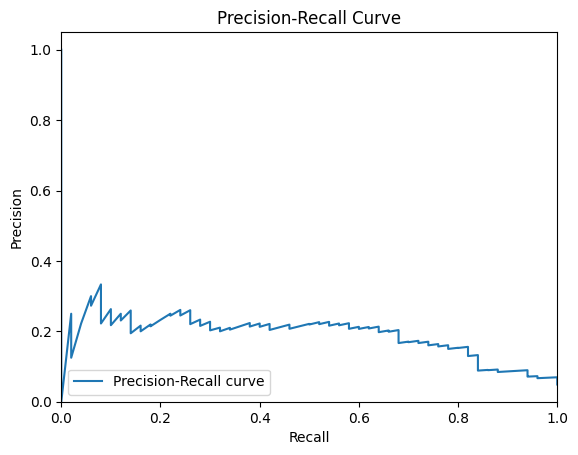

 69%|██████▉   | 9/13 [00:13<00:06,  1.61s/it]


Confusion Matrix:
 [[966   6]
 [ 48   2]]


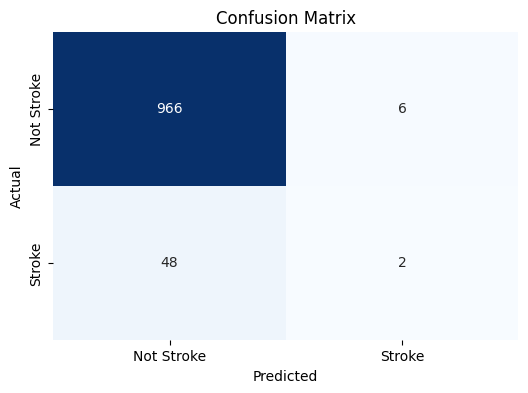


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.25      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.60      0.52      0.52      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8273251028806584


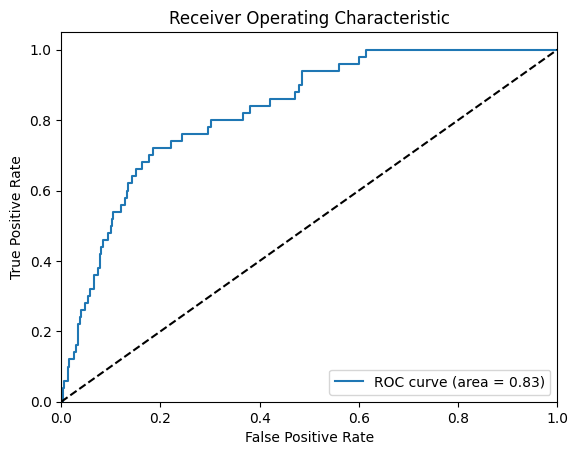

PR AUC: 0.18721265190044567


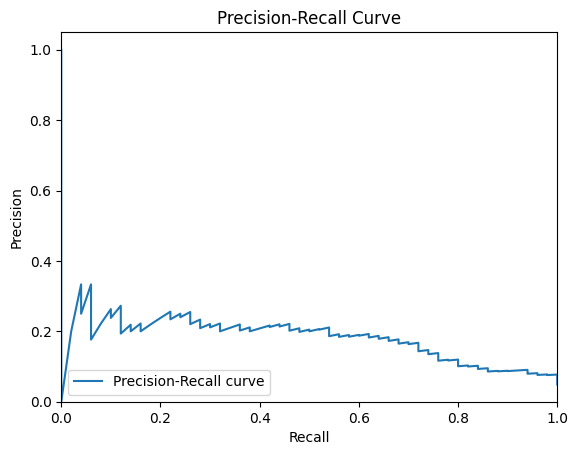

 77%|███████▋  | 10/13 [00:15<00:04,  1.46s/it]


Confusion Matrix:
 [[942  30]
 [ 41   9]]


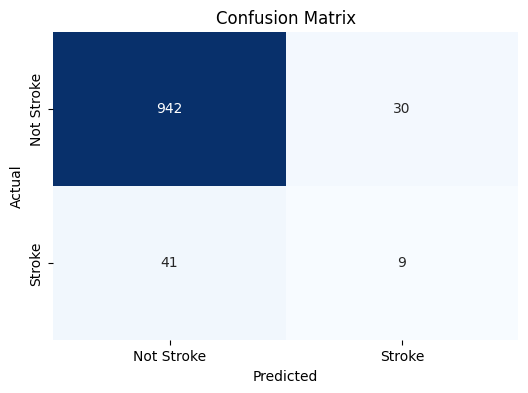


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.97      0.96       972
      Stroke       0.23      0.18      0.20        50

    accuracy                           0.93      1022
   macro avg       0.59      0.57      0.58      1022
weighted avg       0.92      0.93      0.93      1022

ROC-AUC: 0.7843415637860082


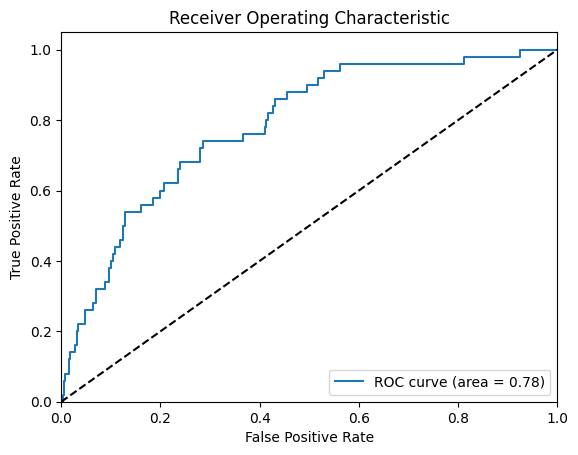

PR AUC: 0.1639478475971082


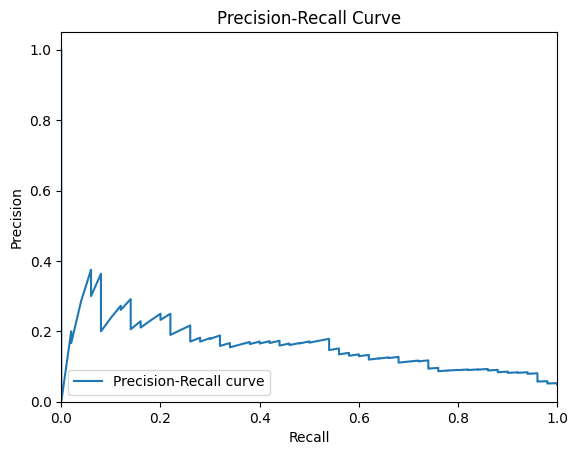

 85%|████████▍ | 11/13 [00:16<00:02,  1.34s/it]


Confusion Matrix:
 [[966   6]
 [ 47   3]]


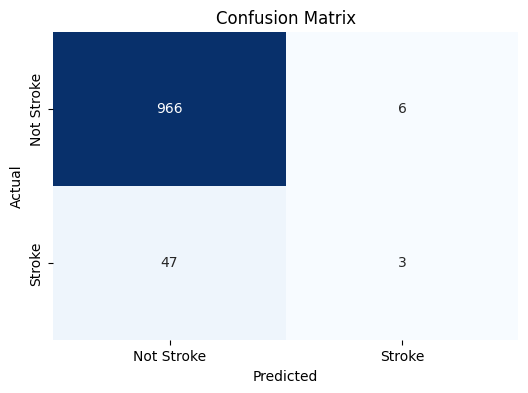


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.33      0.06      0.10        50

    accuracy                           0.95      1022
   macro avg       0.64      0.53      0.54      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.8166255144032921


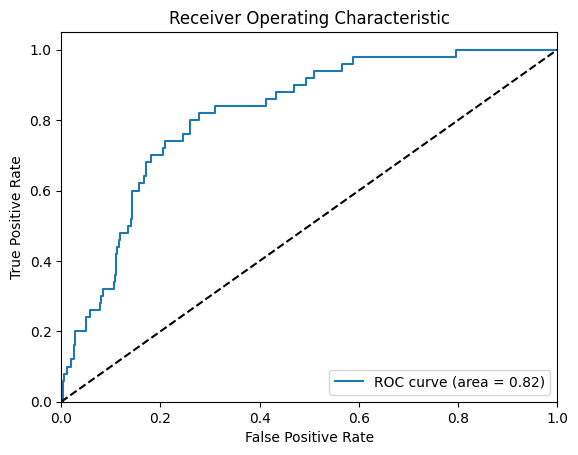

PR AUC: 0.17402891032085158


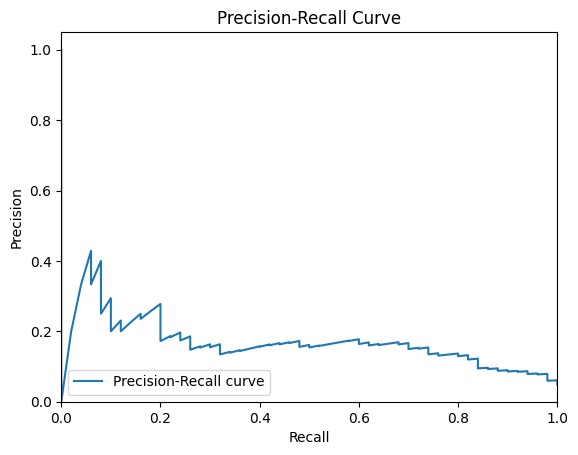

 92%|█████████▏| 12/13 [00:21<00:02,  2.54s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 199, number of negative: 3889
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002012 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 638
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.048679 -> initscore=-2.972603
[LightGBM] [Info] Start training from score -2.972603

Confusion Matrix:
 [[965   7]
 [ 48   2]]


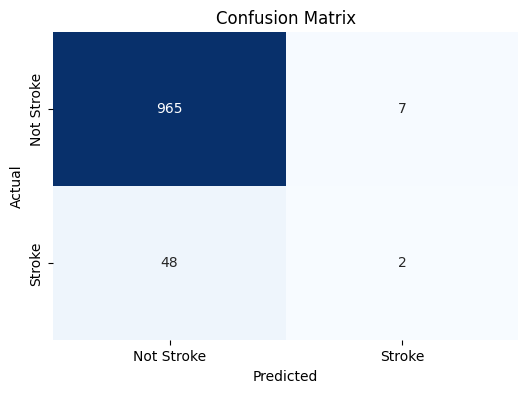


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.99      0.97       972
      Stroke       0.22      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.59      0.52      0.52      1022
weighted avg       0.92      0.95      0.93      1022

ROC-AUC: 0.83


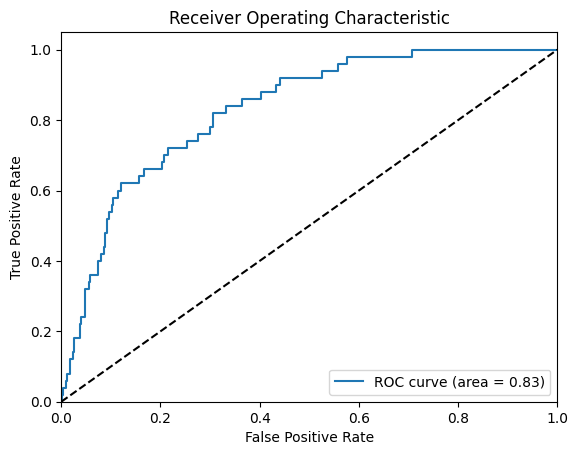

PR AUC: 0.1938575109829555


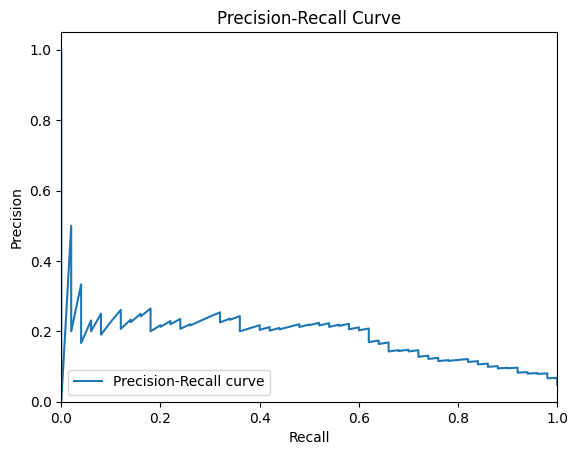

100%|██████████| 13/13 [00:22<00:00,  1.71s/it]


In [32]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


In [33]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [34]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Random Forest,0.896037,0.868885,0.311667,0.181818,0.939698,0.48,0.468085,0.263736,0.916751,0.684444,0.805967,0.175003
Logistic Regression,0.738992,0.746575,0.135906,0.138408,0.814070,0.80,0.232926,0.235988,0.774610,0.771914,0.843807,0.268202
XGBoost,0.997065,0.930528,0.943128,0.230769,1.000000,0.18,0.970732,0.202247,0.998457,0.574568,0.784342,0.163948
Decision Tree,1.000000,0.911937,1.000000,0.166667,1.000000,0.20,1.000000,0.181818,1.000000,0.574280,0.574280,0.072472
Naive Bayes,0.422701,0.432485,0.077434,0.075321,0.994975,0.94,0.143687,0.139466,0.694196,0.673189,0.795453,0.171939
CatBoost,0.977006,0.948141,1.000000,0.333333,0.527638,0.06,0.690789,0.101695,0.763819,0.526914,0.816626,0.174029
Hist Gradient Boosting,0.993640,0.947162,1.000000,0.250000,0.869347,0.04,0.930108,0.068966,0.934673,0.516914,0.827325,0.187213
LightGBM,0.993640,0.946184,0.988701,0.222222,0.879397,0.04,0.930851,0.067797,0.939441,0.516399,0.830000,0.193858
Extra Trees,1.000000,0.943249,1.000000,0.166667,1.000000,0.04,1.000000,0.064516,1.000000,0.514856,0.709084,0.109417
Gradient Boosting,0.960127,0.949119,1.000000,0.250000,0.180905,0.02,0.306383,0.037037,0.590452,0.508457,0.835576,0.196507


<Axes: >

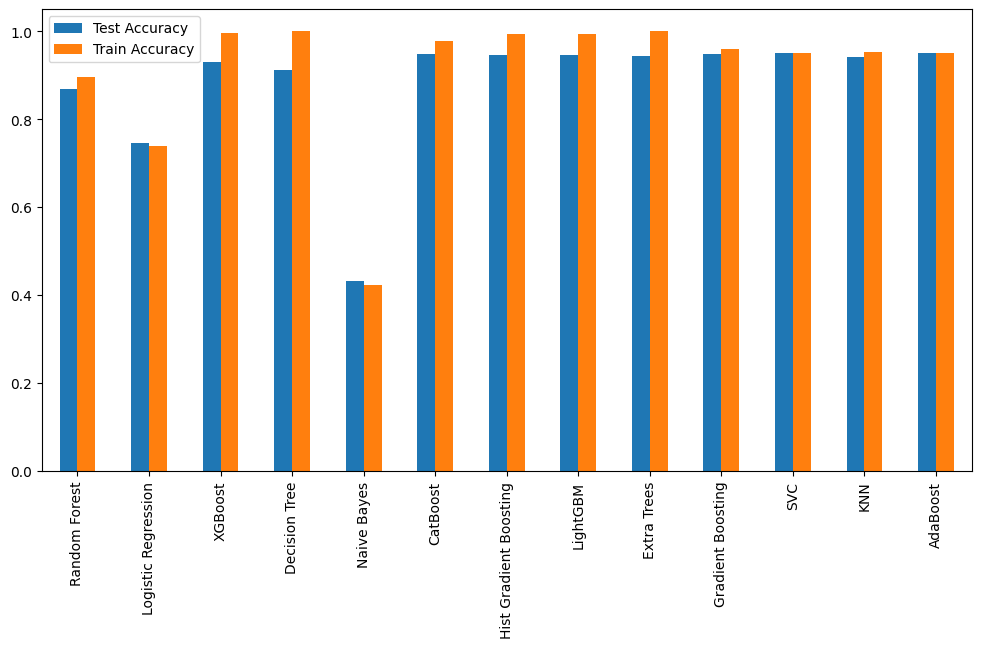

In [35]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

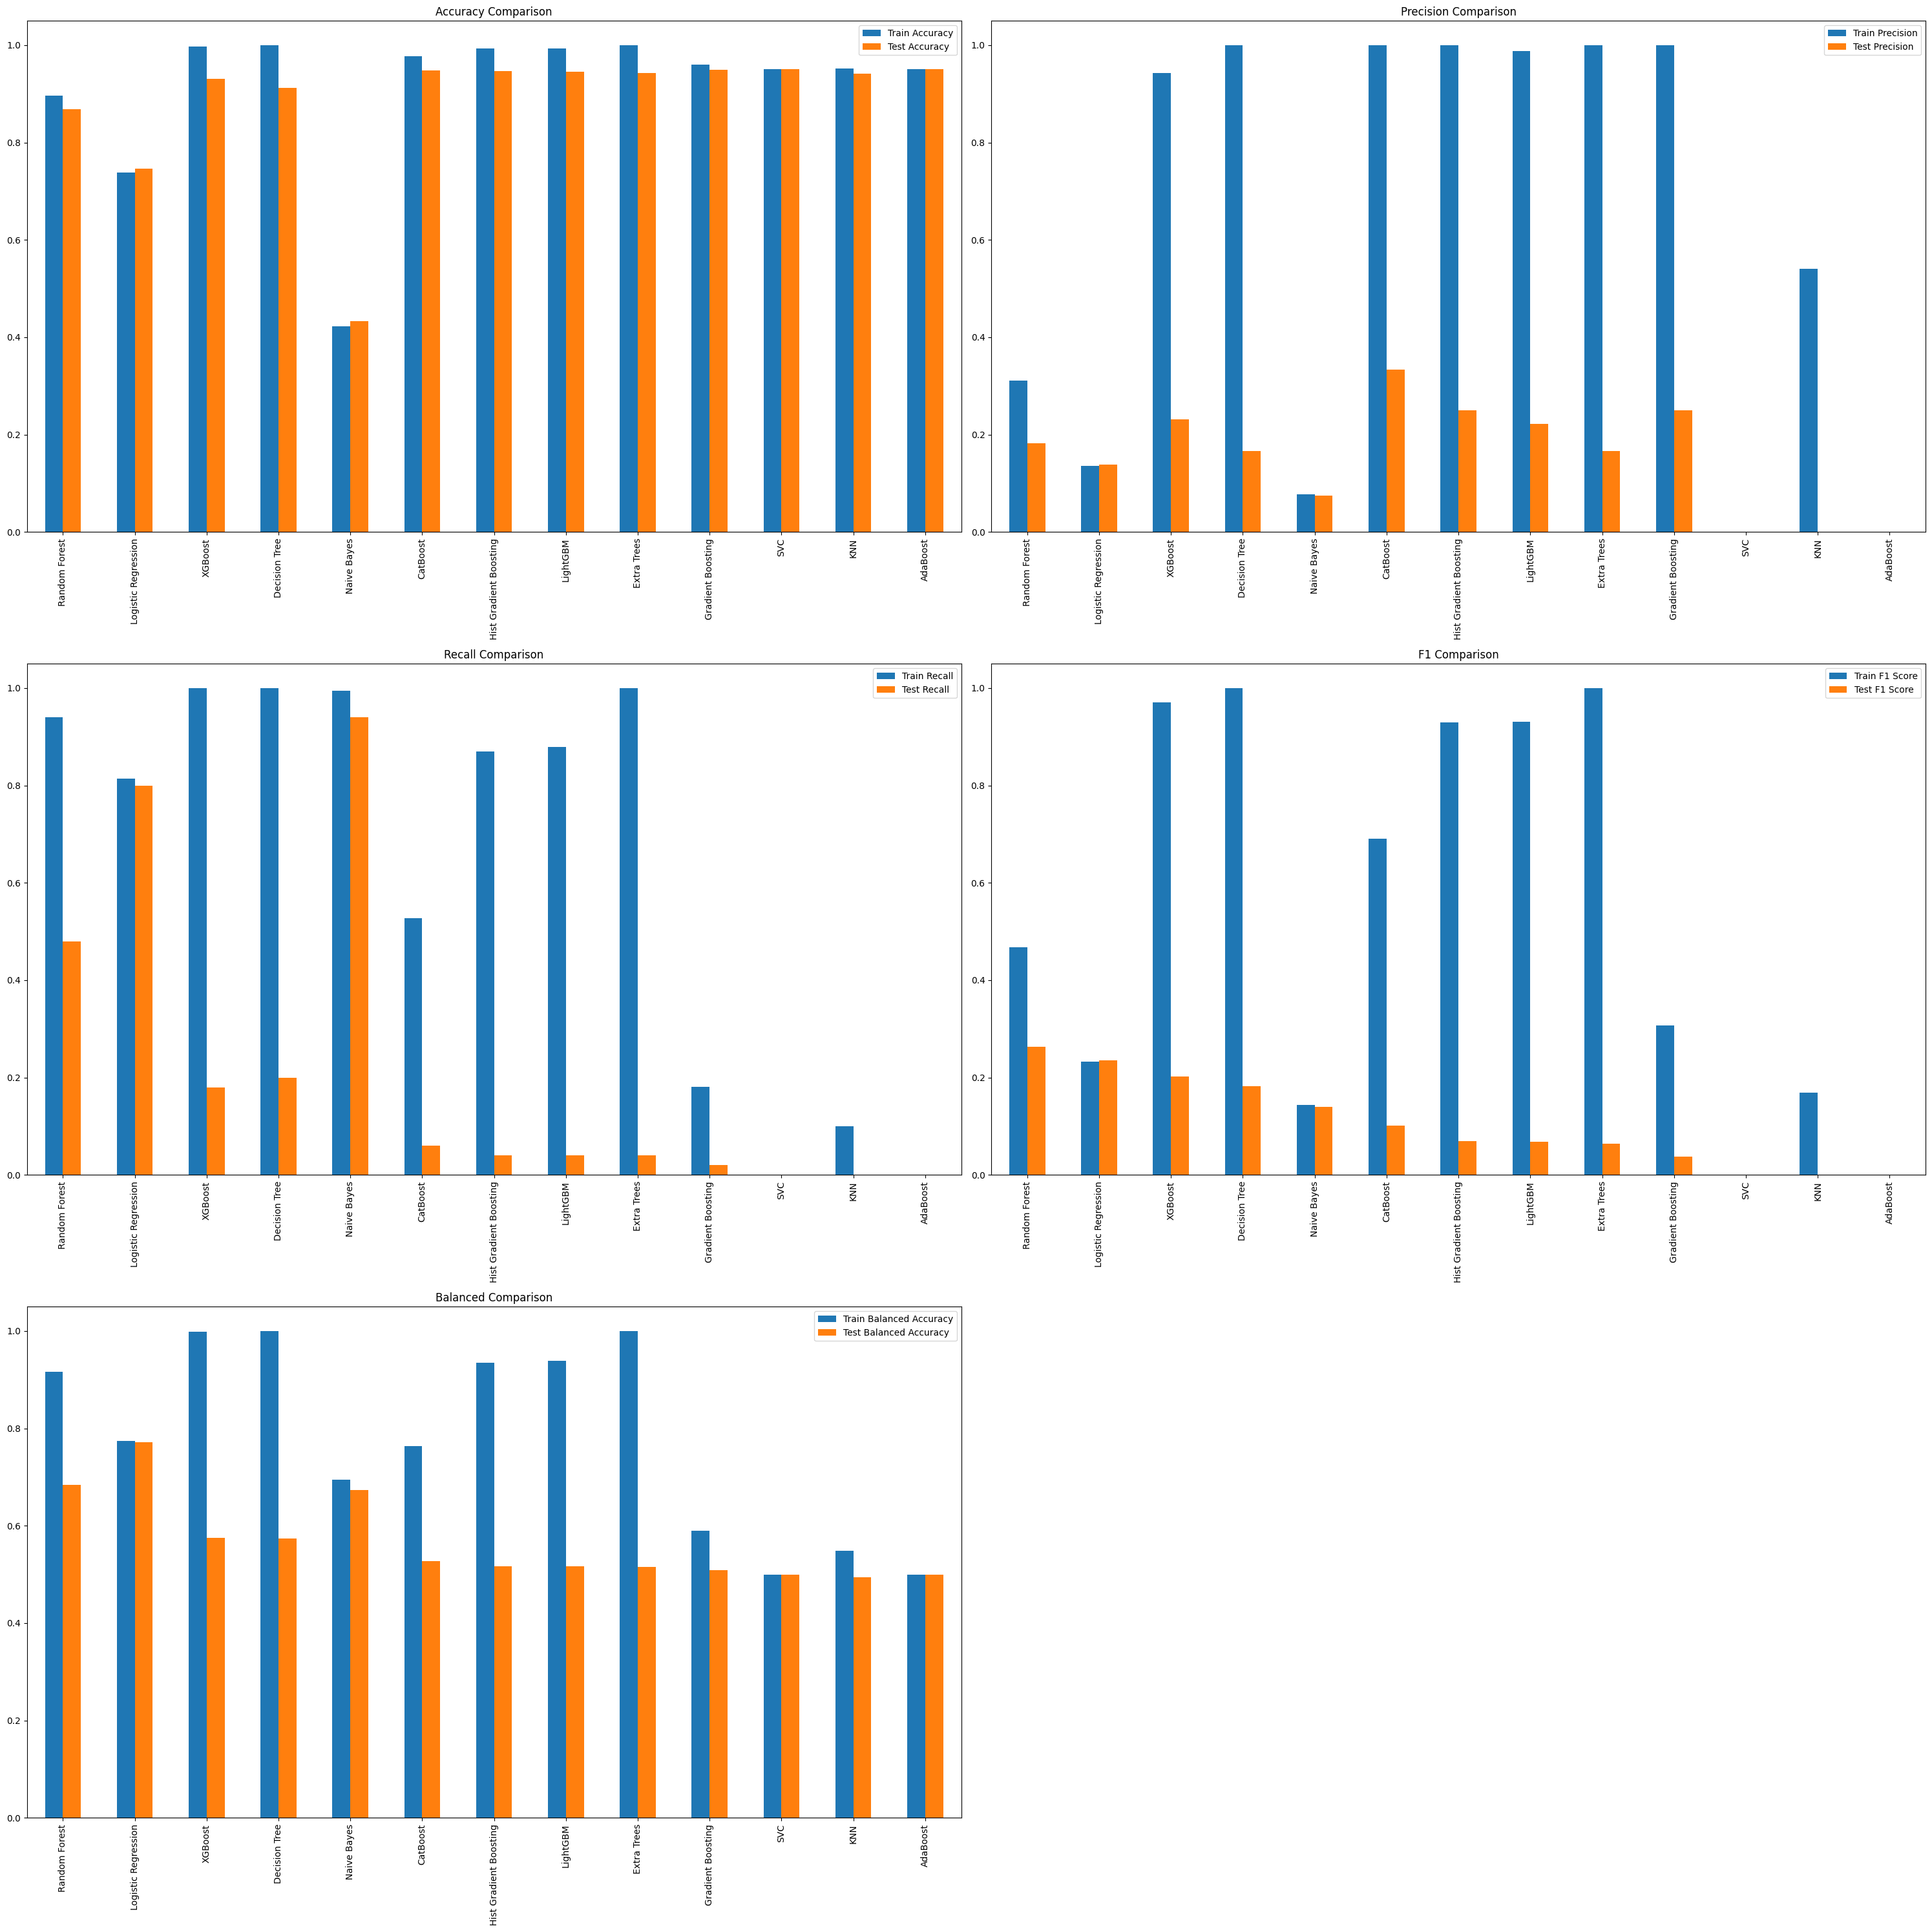

In [36]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

In [37]:
from sklearn.decomposition import PCA

pca = PCA(n_components=10)
x_train_pca = pca.fit_transform(x_train)
x_test_pca = pca.transform(x_test)

x_train_pca.shape

(4088, 10)